<a href="https://colab.research.google.com/github/VALTOm07/ML_Challenge02_MineriaDeAsteroides/blob/main/pipeline_razonamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de razonamiento, búsqueda y resultados

**Caso:** minería de asteroides. Este notebook implementa un modelo conceptual de búsqueda en anchura (BFS). Los estados y las reglas son académicos; no prueban la viabilidad de una misión real.

## 1. Definición del problema

Explorar una ruta conceptual desde el inicio de la evaluación hasta un resultado preliminar. La fuente del caso no proporciona datos suficientes para decidir la rentabilidad real de una misión.

In [1]:
from collections import deque

estados = {
    'S0': 'Inicio',
    'S1': 'Tecnología revisada',
    'S2': 'Economía calculada',
    'S3': 'Restricciones revisadas',
    'S4': 'Evaluación preliminar favorable',
    'S5': 'Requiere más evidencia',
}

# Transiciones posibles según el diagrama conceptual.
# No se asignan valores ni se evalúan umbrales porque no hay datos para ello.
grafo = {
    'S0': ['S1', 'S5'],  # Tecnología cumple el umbral / requiere más evidencia
    'S1': ['S2', 'S5'],  # Hay datos económicos / faltan datos
    'S2': ['S3', 'S5'],  # Se pueden revisar restricciones / falta evidencia
    'S3': ['S4', 'S5'],  # Criterios cumplidos / criterios no cumplidos
    'S4': [],
    'S5': [],
}

print('Estados:', estados)
print('Transiciones:', grafo)

Estados: {'S0': 'Inicio', 'S1': 'Tecnología revisada', 'S2': 'Economía calculada', 'S3': 'Restricciones revisadas', 'S4': 'Evaluación preliminar favorable', 'S5': 'Requiere más evidencia'}
Transiciones: {'S0': ['S1', 'S5'], 'S1': ['S2', 'S5'], 'S2': ['S3', 'S5'], 'S3': ['S4', 'S5'], 'S4': [], 'S5': []}


## 2. Espacio de estados y restricciones

- **Estados:** S0–S5.
- **Operadores:** evaluar tecnología, calcular economía, revisar restricciones y clasificar resultado.
- **Transiciones:** cada etapa puede continuar a la siguiente o terminar en S5 si no se cumple la condición indicada en el diagrama.
- **Restricciones:** los umbrales y condiciones son conceptuales; no se inventan valores ni se evalúan condiciones reales porque no se proporcionan datos suficientes.
- **Importante:** BFS explora las transiciones posibles del grafo. No determina por sí mismo si una condición tecnológica, económica o regulatoria se cumple.

In [2]:
def busqueda_anchura(inicio, objetivo, grafo):
    """BFS: retorna estados visitados y camino al objetivo, si existe."""
    cola = deque([inicio])
    padre = {inicio: None}
    visitados = []

    while cola:
        actual = cola.popleft()
        visitados.append(actual)
        if actual == objetivo:
            break
        for vecino in grafo.get(actual, []):
            if vecino not in padre:
                padre[vecino] = actual
                cola.append(vecino)

    camino = []
    if objetivo in padre:
        actual = objetivo
        while actual is not None:
            camino.append(actual)
            actual = padre[actual]
        camino.reverse()
    return visitados, camino

objetivo = 'S4'
visitados, camino = busqueda_anchura('S0', objetivo, grafo)
print('Orden de visita:', visitados)
print('Camino encontrado:', camino)
print('Interpretación:', ' -> '.join(estados[s] for s in camino) if camino else 'No se encontró ruta')
print('Nota: la ruta es posible según el grafo; no confirma que se cumplan condiciones reales.')

Orden de visita: ['S0', 'S1', 'S5', 'S2', 'S3', 'S4']
Camino encontrado: ['S0', 'S1', 'S2', 'S3', 'S4']
Interpretación: Inicio -> Tecnología revisada -> Economía calculada -> Restricciones revisadas -> Evaluación preliminar favorable
Nota: la ruta es posible según el grafo; no confirma que se cumplan condiciones reales.


## 3. Visualización del grafo

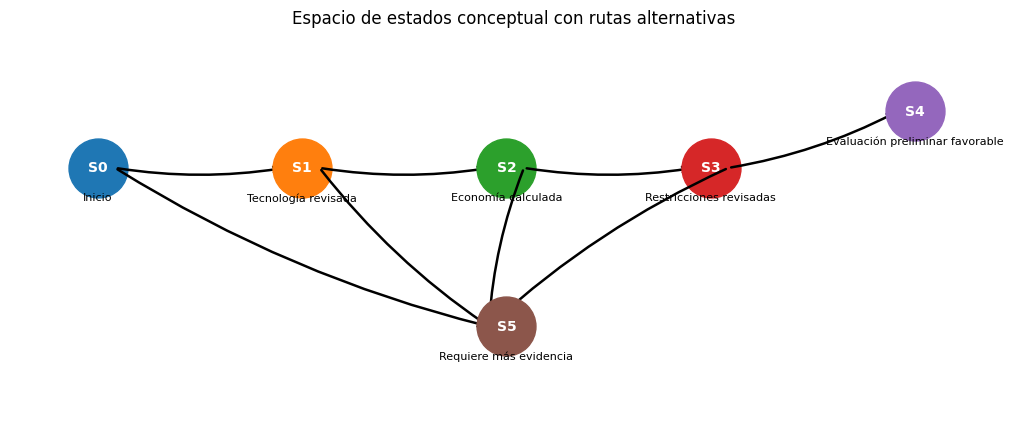

In [3]:
import matplotlib.pyplot as plt

pos = {
    'S0': (0, 0),
    'S1': (1.4, 0),
    'S2': (2.8, 0),
    'S3': (4.2, 0),
    'S4': (5.6, 0.5),
    'S5': (2.8, -1.4),
}
fig, ax = plt.subplots(figsize=(13, 5))
for origen, destinos in grafo.items():
    x1, y1 = pos[origen]
    ax.scatter(x1, y1, s=1800, zorder=3)
    ax.text(x1, y1, origen, ha='center', va='center', color='white', weight='bold')
    for destino in destinos:
        x2, y2 = pos[destino]
        ax.annotate(
            '',
            xy=(x2 - 0.12, y2),
            xytext=(x1 + 0.12, y1),
            arrowprops=dict(arrowstyle='->', lw=1.8, connectionstyle='arc3,rad=0.08')
        )
for s, (x, y) in pos.items():
    ax.text(x, y - 0.22, estados[s], ha='center', va='top', fontsize=8, wrap=True)
ax.set_xlim(-0.6, 6.3)
ax.set_ylim(-2.2, 1.2)
ax.axis('off')
ax.set_title('Espacio de estados conceptual con rutas alternativas')
plt.show()

## 4. Resultado y límites

BFS encuentra una ruta según las transiciones definidas. En este grafo existe una ruta posible desde S0 hasta S4, pero también hay rutas alternativas hacia S5 cuando una condición no se cumple o falta evidencia. Como no se proporcionan datos concretos, el código no decide qué rama representa una misión real. El modelo no compara la rentabilidad de distintas misiones ni demuestra la viabilidad o inviabilidad económica de una misión.